# CLNLP Experiment 6
## GloVe Word Embeddings & N-gram Language Model

**Objectives**
1. Implement the **GloVe (Global Vectors for Word Representation)** algorithm to generate word embeddings from a text corpus and find the words most similar to **"king"**.
   - **Part A.1** – GloVe implemented **from scratch** (no pretrained model).
   - **Part A.2** – Using a **pretrained GloVe model** through **Gensim**.
2. **Part B** – Implement a **statistical language model from scratch** using the **N-gram** approach to predict the next word in a sequence.

Dataset: `glove_corpus (1).txt` (provided with the experiment).

---
# Part A.1 – GloVe from Scratch

### Theory
GloVe learns word vectors from the **global word–word co-occurrence matrix** $X$, where $X_{ij}$ is how often word $j$ appears in the context of word $i$.
It trains word vectors $w_i$, context vectors $\tilde{w}_j$ and biases $b_i, \tilde{b}_j$ to minimise the weighted least-squares objective:

$$J = \sum_{i,j:\,X_{ij}>0} f(X_{ij})\left(w_i^T\tilde{w}_j + b_i + \tilde{b}_j - \log X_{ij}\right)^2$$

with the weighting function

$$f(x) = \begin{cases}(x/x_{max})^{\alpha} & x < x_{max}\\ 1 & \text{otherwise}\end{cases}$$

The final embedding of a word is $w_i + \tilde{w}_i$.

**Steps:** load corpus → preprocess → build vocabulary → build co-occurrence matrix → train with AdaGrad → find similar words.

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

np.random.seed(42)

### Step 1: Load the corpus
The notebook reads `glove_corpus (1).txt` (upload it to Colab if needed). If the file is not found, the same corpus is used from an inline copy.

In [2]:
CORPUS_FILES = ["glove_corpus (1).txt", "glove_corpus.txt", "/content/glove_corpus (1).txt", "/content/glove_corpus.txt"]

FALLBACK_CORPUS = '''The king rules the kingdom.
The queen rules the kingdom.
The king is a powerful man.
The queen is a wise woman.
The man is strong and brave.
The woman is intelligent and kind.
The king and queen rule together.
The man and woman live in the kingdom.
The prince is the son of the king.
The princess is the daughter of the queen.
The king lives in a royal palace.
The queen lives in a royal palace.
A doctor treats a patient.
A teacher teaches students in a school.
Students read books and learn new things.
A computer processes data and information.
A computer scientist develops software.
The scientist conducts research in a laboratory.
The cat drinks milk.
The dog eats food.
The cat and dog live in a house.
The sun gives light and heat.
The moon shines at night.
The earth revolves around the sun.'''

raw_text = None
for f in CORPUS_FILES:
    if os.path.exists(f):
        with open(f, encoding="utf-8") as fh:
            raw_text = fh.read()
        print("Loaded corpus from:", f)
        break
if raw_text is None:
    raw_text = FALLBACK_CORPUS
    print("Corpus file not found - using inline copy of the corpus.")

print(raw_text)

Loaded corpus from: glove_corpus (1).txt
The king rules the kingdom.
The queen rules the kingdom.
The king is a powerful man.
The queen is a wise woman.
The man is strong and brave.
The woman is intelligent and kind.
The king and queen rule together.
The man and woman live in the kingdom.
The prince is the son of the king.
The princess is the daughter of the queen.
The king lives in a royal palace.
The queen lives in a royal palace.
A doctor treats a patient.
A teacher teaches students in a school.
Students read books and learn new things.
A computer processes data and information.
A computer scientist develops software.
The scientist conducts research in a laboratory.
The cat drinks milk.
The dog eats food.
The cat and dog live in a house.
The sun gives light and heat.
The moon shines at night.
The earth revolves around the sun.


### Step 2: Preprocessing
Lower-casing, tokenisation and removal of very frequent function words (`the`, `a`, `is`, ...). On such a small corpus these words co-occur with everything and would dominate the embeddings.

In [3]:
STOPWORDS = {"the", "a", "an", "is", "and", "in", "of", "at", "to", "around"}

def preprocess(text):
    sentences = []
    for line in text.lower().split("\n"):
        tokens = re.findall(r"[a-z]+", line)
        tokens = [t for t in tokens if t not in STOPWORDS]
        if tokens:
            sentences.append(tokens)
    return sentences

sentences = preprocess(raw_text)
for s in sentences[:6]:
    print(s)
print("...\nNumber of sentences:", len(sentences))

['king', 'rules', 'kingdom']
['queen', 'rules', 'kingdom']
['king', 'powerful', 'man']
['queen', 'wise', 'woman']
['man', 'strong', 'brave']
['woman', 'intelligent', 'kind']
...
Number of sentences: 24


### Step 3: Build the vocabulary

In [4]:
word_counts = Counter(w for s in sentences for w in s)
vocab = sorted(word_counts)
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
V = len(vocab)

print("Vocabulary size:", V)
print("Most common words:", word_counts.most_common(10))

Vocabulary size: 60
Most common words: [('king', 5), ('queen', 5), ('kingdom', 3), ('man', 3), ('woman', 3), ('rules', 2), ('live', 2), ('lives', 2), ('royal', 2), ('palace', 2)]


### Step 4: Build the co-occurrence matrix
A symmetric context window is used; a context word at distance $d$ contributes $1/d$ to the count (as in the original GloVe paper).

In [5]:
WINDOW_SIZE = 3

def build_cooccurrence(sentences, word2idx, window_size):
    X = np.zeros((len(word2idx), len(word2idx)), dtype=np.float64)
    for sent in sentences:
        ids = [word2idx[w] for w in sent]
        for center_pos, center_id in enumerate(ids):
            start = max(0, center_pos - window_size)
            end = min(len(ids), center_pos + window_size + 1)
            for ctx_pos in range(start, end):
                if ctx_pos == center_pos:
                    continue
                distance = abs(ctx_pos - center_pos)
                X[center_id, ids[ctx_pos]] += 1.0 / distance
    return X

X = build_cooccurrence(sentences, word2idx, WINDOW_SIZE)
print("Co-occurrence matrix shape:", X.shape)
print("Non-zero entries:", int((X > 0).sum()))

# show a part of the matrix for the 'royal' words
show = ["king", "queen", "man", "woman", "prince", "princess", "kingdom", "palace", "royal"]
pd.DataFrame(X[[word2idx[w] for w in show]][:, [word2idx[w] for w in show]],
             index=show, columns=show).round(2)

Co-occurrence matrix shape: (60, 60)
Non-zero entries: 214


,king,queen,man,woman,prince,princess,kingdom,palace,royal
king,0.00,1.00,0.50,0.0,0.5,0.0,0.50,0.33,0.5
queen,1.00,0.00,0.00,0.5,0.0,0.5,0.50,0.33,0.5
man,0.50,0.00,0.00,1.0,0.0,0.0,0.33,0.00,0.0
woman,0.00,0.50,1.00,0.0,0.0,0.0,0.50,0.00,0.0
prince,0.50,0.00,0.00,0.0,0.0,0.0,0.00,0.00,0.0
princess,0.00,0.50,0.00,0.0,0.0,0.0,0.00,0.00,0.0
kingdom,0.50,0.50,0.33,0.5,0.0,0.0,0.00,0.00,0.0
palace,0.33,0.33,0.00,0.0,0.0,0.0,0.00,0.00,2.0
royal,0.50,0.50,0.00,0.0,0.0,0.0,0.00,2.00,0.0


### Step 5: Train the GloVe model
Only the non-zero entries of $X$ are used. Parameters are updated with **AdaGrad** (as in the original paper).

In [6]:
class GloVe:
    def __init__(self, vocab_size, embedding_dim=30, x_max=5, alpha=0.75, lr=0.05, seed=42):
        rng = np.random.default_rng(seed)
        self.V, self.d = vocab_size, embedding_dim
        self.x_max, self.alpha, self.lr = x_max, alpha, lr
        # word vectors, context vectors and biases
        self.W  = (rng.random((vocab_size, embedding_dim)) - 0.5) / embedding_dim
        self.Wc = (rng.random((vocab_size, embedding_dim)) - 0.5) / embedding_dim
        self.b  = np.zeros(vocab_size)
        self.bc = np.zeros(vocab_size)
        # AdaGrad accumulators
        self.gW, self.gWc = np.ones_like(self.W), np.ones_like(self.Wc)
        self.gb, self.gbc = np.ones_like(self.b), np.ones_like(self.bc)

    def weight_fn(self, x):
        return np.where(x < self.x_max, (x / self.x_max) ** self.alpha, 1.0)

    def fit(self, X, epochs=1000, verbose_every=100):
        rows, cols = np.nonzero(X)
        x_vals = X[rows, cols]
        log_x = np.log(x_vals)
        f_x = self.weight_fn(x_vals)
        history = []
        for epoch in range(1, epochs + 1):
            perm = np.random.permutation(len(rows))
            total_loss = 0.0
            for k in perm:
                i, j = rows[k], cols[k]
                diff = self.W[i] @ self.Wc[j] + self.b[i] + self.bc[j] - log_x[k]
                total_loss += 0.5 * f_x[k] * diff ** 2
                grad = f_x[k] * diff
                grad_wi = grad * self.Wc[j]
                grad_wj = grad * self.W[i]
                # AdaGrad updates
                self.W[i]  -= self.lr * grad_wi / np.sqrt(self.gW[i])
                self.Wc[j] -= self.lr * grad_wj / np.sqrt(self.gWc[j])
                self.b[i]  -= self.lr * grad / np.sqrt(self.gb[i])
                self.bc[j] -= self.lr * grad / np.sqrt(self.gbc[j])
                self.gW[i]  += grad_wi ** 2
                self.gWc[j] += grad_wj ** 2
                self.gb[i]  += grad ** 2
                self.gbc[j] += grad ** 2
            history.append(total_loss)
            if epoch % verbose_every == 0 or epoch == 1:
                print(f"Epoch {epoch:4d} | loss = {total_loss:.4f}")
        return history

    @property
    def embeddings(self):
        return self.W + self.Wc

glove = GloVe(V, embedding_dim=30, x_max=5, alpha=0.75, lr=0.05)
loss_history = glove.fit(X, epochs=1000, verbose_every=100)

Epoch    1 | loss = 5.6657
Epoch  100 | loss = 2.2947
Epoch  200 | loss = 1.3300
Epoch  300 | loss = 0.3971
Epoch  400 | loss = 0.0610
Epoch  500 | loss = 0.0157
Epoch  600 | loss = 0.0061
Epoch  700 | loss = 0.0028
Epoch  800 | loss = 0.0015
Epoch  900 | loss = 0.0008
Epoch 1000 | loss = 0.0005


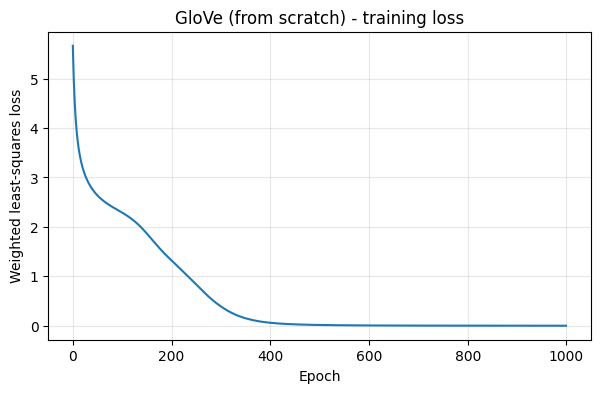

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch"); plt.ylabel("Weighted least-squares loss")
plt.title("GloVe (from scratch) - training loss")
plt.grid(alpha=0.3)
plt.show()

### Step 6: Find the most similar words to "king"
Cosine similarity between the final embeddings $w_i + \tilde{w}_i$.

In [8]:
embeddings = glove.embeddings
norm_emb = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)

def most_similar(word, topn=5):
    if word not in word2idx:
        raise KeyError(f"'{word}' not in vocabulary")
    sims = norm_emb @ norm_emb[word2idx[word]]
    order = np.argsort(-sims)
    return [(idx2word[i], float(sims[i])) for i in order if idx2word[i] != word][:topn]

print("Top words most similar to 'king' (GloVe from scratch):")
for w, s in most_similar("king", topn=8):
    print(f"  {w:<12s} {s:.4f}")

Top words most similar to 'king' (GloVe from scratch):
  son          0.9689
  powerful     0.9370
  queen        0.9320
  prince       0.9024
  wise         0.8971
  daughter     0.7588
  lives        0.7576
  treats       0.4686


In [9]:
for w in ["queen", "man", "cat", "computer", "sun"]:
    print(f"{w:<9s}->", [f"{x} ({s:.2f})" for x, s in most_similar(w, topn=4)])

queen    -> ['son (0.94)', 'king (0.93)', 'wise (0.92)', 'powerful (0.88)']
man      -> ['woman (0.89)', 'strong (0.76)', 'teacher (0.64)', 'teaches (0.62)']
cat      -> ['dog (0.94)', 'drinks (0.81)', 'treats (0.48)', 'man (0.48)']
computer -> ['processes (0.99)', 'scientist (0.88)', 'conducts (0.82)', 'wise (0.25)']
sun      -> ['gives (1.00)', 'revolves (0.94)', 'earth (0.59)', 'teacher (0.24)']


In [10]:
def cosine(w1, w2):
    return float(norm_emb[word2idx[w1]] @ norm_emb[word2idx[w2]])

pairs = [("king", "queen"), ("king", "prince"), ("king", "palace"), ("king", "cat"), ("king", "computer")]
for a, b in pairs:
    print(f"similarity({a}, {b}) = {cosine(a, b):.4f}")

similarity(king, queen) = 0.9320
similarity(king, prince) = 0.9024
similarity(king, palace) = -0.9618
similarity(king, cat) = 0.1404
similarity(king, computer) = 0.1973


### Step 7: Visualise the embeddings (PCA → 2-D)

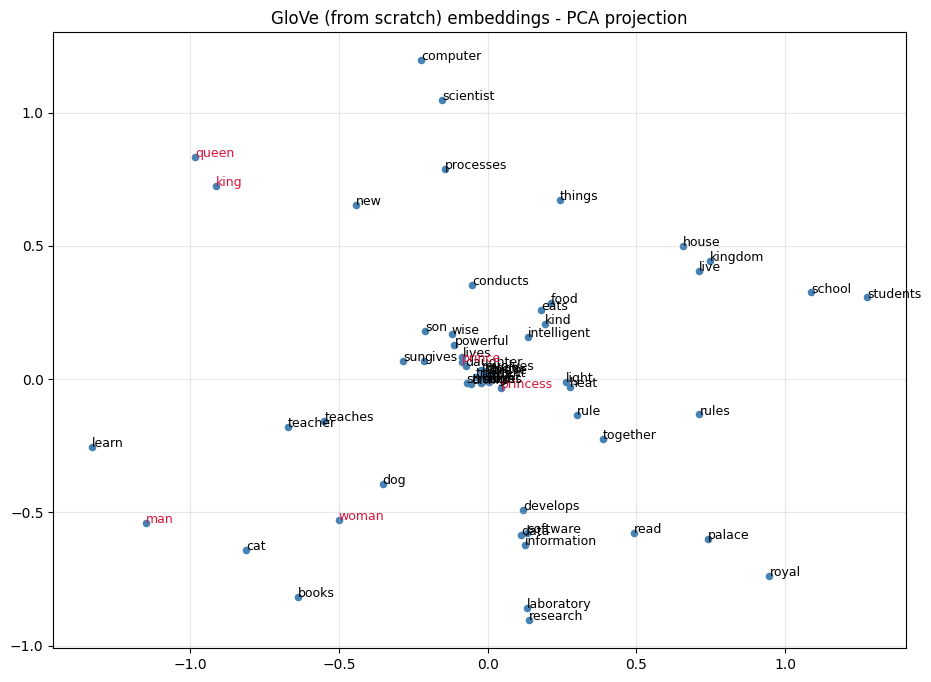

In [11]:
centered = embeddings - embeddings.mean(axis=0)
U, S, Vt = np.linalg.svd(centered, full_matrices=False)
coords = centered @ Vt[:2].T

plt.figure(figsize=(11, 8))
plt.scatter(coords[:, 0], coords[:, 1], s=20, c="steelblue")
for i, w in idx2word.items():
    color = "crimson" if w in {"king", "queen", "prince", "princess", "man", "woman"} else "black"
    plt.annotate(w, (coords[i, 0], coords[i, 1]), fontsize=9, color=color)
plt.title("GloVe (from scratch) embeddings - PCA projection")
plt.grid(alpha=0.3)
plt.show()

---
# Part A.2 – Using a Pretrained GloVe Model (Gensim)

Gensim's downloader provides GloVe vectors trained on **Wikipedia 2014 + Gigaword 5** (6B tokens, 400k vocabulary). We use the 100-dimensional version `glove-wiki-gigaword-100`.

In [12]:
!pip install -q gensim


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import gensim.downloader as api

glove_pretrained = api.load("glove-wiki-gigaword-100")   # ~128 MB download
print("Vocabulary size:", len(glove_pretrained.key_to_index))
print("Vector dimension:", glove_pretrained.vector_size)

[==================================================] 100.0% 128.1/128.1MB downloaded
Vocabulary size: 400000
Vector dimension: 100


In [14]:
print("Top 10 words most similar to 'king' (pretrained GloVe):")
for w, s in glove_pretrained.most_similar("king", topn=10):
    print(f"  {w:<12s} {s:.4f}")

Top 10 words most similar to 'king' (pretrained GloVe):
  prince       0.7682
  queen        0.7508
  son          0.7021
  brother      0.6986
  monarch      0.6978
  throne       0.6920
  kingdom      0.6811
  father       0.6802
  emperor      0.6713
  ii           0.6676


In [15]:
# Word analogy: king - man + woman = ?
print("king - man + woman =", glove_pretrained.most_similar(positive=["king", "woman"], negative=["man"], topn=5))
print("prince - man + woman =", glove_pretrained.most_similar(positive=["prince", "woman"], negative=["man"], topn=3))

for a, b in [("king", "queen"), ("king", "prince"), ("king", "palace"), ("king", "cat"), ("king", "computer")]:
    print(f"similarity({a}, {b}) = {glove_pretrained.similarity(a, b):.4f}")

king - man + woman = [('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473), ('daughter', 0.6594556570053101), ('princess', 0.6520534157752991)]
prince - man + woman = [('princess', 0.7514395117759705), ('daughter', 0.6816167831420898), ('queen', 0.6580643653869629)]
similarity(king, queen) = 0.7508
similarity(king, prince) = 0.7682
similarity(king, palace) = 0.5375
similarity(king, cat) = 0.3282
similarity(king, computer) = 0.1984


Most similar to 'king' among the corpus vocabulary (pretrained vectors):
  prince       0.7682
  queen        0.7508
  son          0.7021
  kingdom      0.6811
  royal        0.6034
  princess     0.5742
  daughter     0.5584
  rule         0.5435


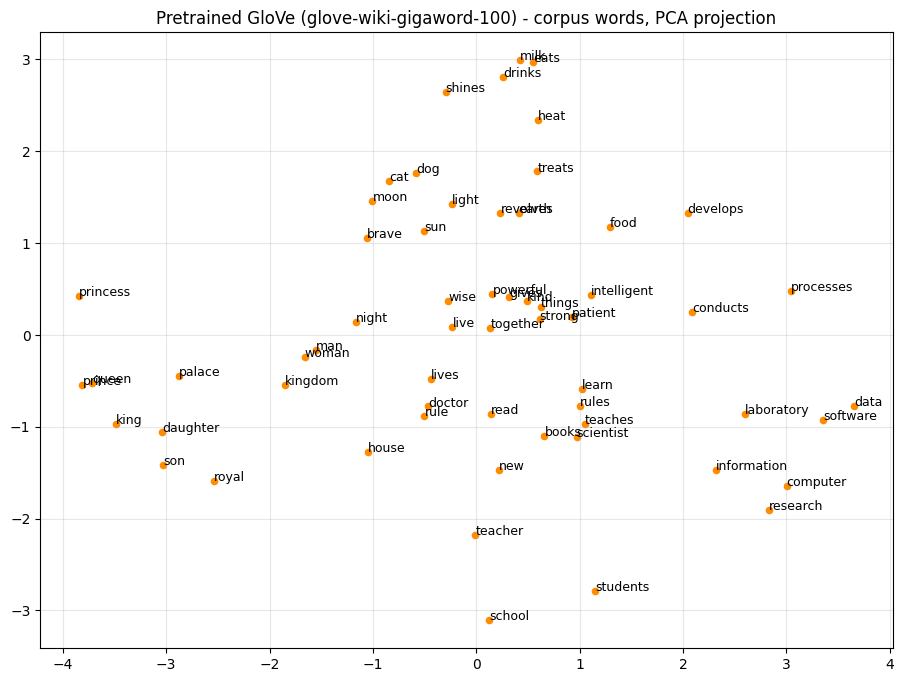

In [16]:
# Pretrained vectors restricted to the words of our corpus
corpus_words = [w for w in vocab if w in glove_pretrained.key_to_index]
sub = np.array([glove_pretrained[w] for w in corpus_words])
sub_norm = sub / np.linalg.norm(sub, axis=1, keepdims=True)
k = corpus_words.index("king")
sims = sub_norm @ sub_norm[k]
print("Most similar to 'king' among the corpus vocabulary (pretrained vectors):")
for i in np.argsort(-sims)[1:9]:
    print(f"  {corpus_words[i]:<12s} {sims[i]:.4f}")

c = sub - sub.mean(axis=0)
_, _, Vt2 = np.linalg.svd(c, full_matrices=False)
xy = c @ Vt2[:2].T
plt.figure(figsize=(11, 8))
plt.scatter(xy[:, 0], xy[:, 1], s=20, c="darkorange")
for i, w in enumerate(corpus_words):
    plt.annotate(w, (xy[i, 0], xy[i, 1]), fontsize=9)
plt.title("Pretrained GloVe (glove-wiki-gigaword-100) - corpus words, PCA projection")
plt.grid(alpha=0.3)
plt.show()

In [17]:
scratch_top = most_similar("king", topn=5)
pre_top = glove_pretrained.most_similar("king", topn=5)
pd.DataFrame({
    "GloVe from scratch": [f"{w} ({s:.2f})" for w, s in scratch_top],
    "Pretrained GloVe (Gensim)": [f"{w} ({s:.2f})" for w, s in pre_top],
}, index=range(1, 6))

,GloVe from scratch,Pretrained GloVe (Gensim)
1,son (0.97),prince (0.77)
2,powerful (0.94),queen (0.75)
3,queen (0.93),son (0.70)
4,prince (0.90),brother (0.70)
5,wise (0.90),monarch (0.70)


### Observations (Part A)
- The **from-scratch** model only sees a 24-sentence corpus, so the neighbours of *king* are words that share its contexts in this corpus (e.g. *queen*, *prince*, *powerful*, *son*). Results can vary between runs because there is very little data.
- The **pretrained** model, trained on 6 billion tokens, gives semantically rich neighbours (*prince*, *queen*, *monarch*, *throne*, ...) and solves analogies such as *king − man + woman ≈ queen*.
- GloVe combines global co-occurrence statistics (like LSA) with a local prediction-style objective (like Word2Vec); the quality of the embeddings depends heavily on corpus size.

---
# Part B – N-gram Language Model from Scratch

### Theory
An N-gram model approximates the probability of a word using only the previous $N-1$ words (Markov assumption):

$$P(w_i \mid w_1,\dots,w_{i-1}) \approx P(w_i \mid w_{i-N+1},\dots,w_{i-1}) = \frac{C(w_{i-N+1}\dots w_{i})}{C(w_{i-N+1}\dots w_{i-1})}$$

**Laplace (add-k) smoothing** avoids zero probabilities for unseen N-grams:

$$P_{add\text{-}k}(w_i\mid h) = \frac{C(h, w_i) + k}{C(h) + k|V|}$$

The next word is predicted as $\arg\max_w P(w \mid h)$.

In [18]:
ngram_corpus = ("natural language processing is a branch of artificial intelligence."
                "natural language processing enables computers to understand human language."
                "machine learning is a branch of artificial intelligence."
                "deep learning is a part of machine learning."
                "language models learn patterns from text data."
                "a language model predicts the next word in a sentence."
                "natural language processing uses language models."
                "artificial intelligence includes machine learning and deep learning.")

def tokenize_sentences(text):
    sents = [s.strip() for s in text.lower().split(".") if s.strip()]
    return [re.findall(r"[a-z]+", s) for s in sents]

ngram_sentences = tokenize_sentences(ngram_corpus)
for s in ngram_sentences:
    print(s)

['natural', 'language', 'processing', 'is', 'a', 'branch', 'of', 'artificial', 'intelligence']
['natural', 'language', 'processing', 'enables', 'computers', 'to', 'understand', 'human', 'language']
['machine', 'learning', 'is', 'a', 'branch', 'of', 'artificial', 'intelligence']
['deep', 'learning', 'is', 'a', 'part', 'of', 'machine', 'learning']
['language', 'models', 'learn', 'patterns', 'from', 'text', 'data']
['a', 'language', 'model', 'predicts', 'the', 'next', 'word', 'in', 'a', 'sentence']
['natural', 'language', 'processing', 'uses', 'language', 'models']
['artificial', 'intelligence', 'includes', 'machine', 'learning', 'and', 'deep', 'learning']


In [19]:
class NGramLanguageModel:
    def __init__(self, n=2, k=1.0):
        self.n = n          # order of the model
        self.k = k          # add-k smoothing constant
        self.ngram_counts = defaultdict(Counter)   # context tuple -> Counter(next word)
        self.context_counts = Counter()
        self.vocab = set()

    def _pad(self, sent):
        return ["<s>"] * (self.n - 1) + sent + ["</s>"]

    def fit(self, sentences):
        for sent in sentences:
            tokens = self._pad(sent)
            self.vocab.update(tokens)
            for i in range(self.n - 1, len(tokens)):
                context = tuple(tokens[i - self.n + 1:i])
                self.ngram_counts[context][tokens[i]] += 1
                self.context_counts[context] += 1
        self.vocab.discard("<s>")
        return self

    def prob(self, word, context):
        context = tuple(context[-(self.n - 1):]) if self.n > 1 else tuple()
        count = self.ngram_counts[context][word]
        return (count + self.k) / (self.context_counts[context] + self.k * len(self.vocab))

    def next_word_distribution(self, context):
        context = tuple(context)
        if self.n > 1:
            context = (["<s>"] * (self.n - 1) + list(context))[-(self.n - 1):]
        probs = {w: self.prob(w, context) for w in self.vocab}
        return sorted(probs.items(), key=lambda x: -x[1])

    def predict_next(self, text, top_k=3):
        tokens = re.findall(r"[a-z]+", text.lower())
        return self.next_word_distribution(tokens)[:top_k]

    def generate(self, seed_text, max_words=10):
        tokens = re.findall(r"[a-z]+", seed_text.lower())
        for _ in range(max_words):
            word = self.next_word_distribution(tokens)[0][0]
            if word == "</s>":
                break
            tokens.append(word)
        return " ".join(tokens)

    def perplexity(self, sentences):
        log_prob, N = 0.0, 0
        for sent in sentences:
            tokens = self._pad(sent)
            for i in range(self.n - 1, len(tokens)):
                log_prob += np.log(self.prob(tokens[i], tokens[i - self.n + 1:i]))
                N += 1
        return float(np.exp(-log_prob / N))

### Train unigram, bigram and trigram models

In [20]:
models = {n: NGramLanguageModel(n=n, k=0.01).fit(ngram_sentences) for n in [1, 2, 3]}
print("Vocabulary size:", len(models[2].vocab))

bigram_model = models[2]
print("\nSome bigram counts:")
for ctx in [("natural",), ("language",), ("machine",), ("artificial",)]:
    print(f"  {ctx[0]:<11s} -> {dict(bigram_model.ngram_counts[ctx])}")

Vocabulary size: 35

Some bigram counts:
  natural     -> {'language': 3}
  language    -> {'processing': 3, '</s>': 1, 'models': 2, 'model': 1}
  machine     -> {'learning': 3}
  artificial  -> {'intelligence': 3}


In [21]:
# Bigram probability table for a few words
words = ["natural", "language", "processing", "machine", "learning", "artificial", "intelligence", "is"]
table = pd.DataFrame([[bigram_model.prob(w2, [w1]) for w2 in words] for w1 in words],
                     index=words, columns=words)
print("P(column | row) - bigram model")
table.round(3)

P(column | row) - bigram model


,natural,language,processing,machine,learning,artificial,intelligence,is
natural,0.003,0.899,0.003,0.003,0.003,0.003,0.003,0.003
language,0.001,0.001,0.410,0.001,0.001,0.001,0.001,0.001
processing,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.301
machine,0.003,0.003,0.003,0.003,0.899,0.003,0.003,0.003
learning,0.002,0.002,0.002,0.002,0.002,0.002,0.002,0.376
artificial,0.003,0.003,0.003,0.003,0.003,0.003,0.899,0.003
intelligence,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003
is,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003


### Next-word prediction

In [22]:
test_inputs = ["natural language", "artificial", "machine learning is", "deep learning is a",
               "language models", "a language model predicts the", "is a branch of"]

for text in test_inputs:
    print(f"Input: '{text}'")
    for n in [2, 3]:
        preds = models[n].predict_next(text, top_k=3)
        print(f"   {n}-gram -> " + ", ".join(f"{w} ({p:.3f})" for w, p in preds))

Input: 'natural language'
   2-gram -> processing (0.410), models (0.273), </s> (0.137)
   3-gram -> processing (0.899), learn (0.003), natural (0.003)
Input: 'artificial'
   2-gram -> intelligence (0.899), learn (0.003), natural (0.003)
   3-gram -> intelligence (0.748), learn (0.007), natural (0.007)
Input: 'machine learning is'
   2-gram -> a (0.899), learn (0.003), natural (0.003)
   3-gram -> a (0.855), learn (0.004), natural (0.004)
Input: 'deep learning is a'
   2-gram -> branch (0.376), sentence (0.189), part (0.189)
   3-gram -> branch (0.600), part (0.301), learn (0.003)
Input: 'language models'
   2-gram -> learn (0.430), </s> (0.430), natural (0.004)
   3-gram -> learn (0.430), </s> (0.430), natural (0.004)
Input: 'a language model predicts the'
   2-gram -> next (0.748), learn (0.007), natural (0.007)
   3-gram -> next (0.748), learn (0.007), natural (0.007)
Input: 'is a branch of'
   2-gram -> artificial (0.600), machine (0.301), learn (0.003)
   3-gram -> artificial (0.8

### Text generation (greedy decoding)

In [23]:
for seed in ["natural", "machine", "deep learning", "a language"]:
    print(f"{seed!r:16s} -> bigram : {models[2].generate(seed)}")
    print(f"{'':16s}    trigram: {models[3].generate(seed)}")

'natural'        -> bigram : natural language processing uses language processing uses language processing uses language
                    trigram: natural language processing uses language models learn patterns from text data
'machine'        -> bigram : machine learning
                    trigram: machine learning and deep learning
'deep learning'  -> bigram : deep learning
                    trigram: deep learning
'a language'     -> bigram : a language processing uses language processing uses language processing uses language processing
                    trigram: a language model predicts the next word in a sentence


### Evaluation using perplexity

In [24]:
test_sentences = tokenize_sentences("natural language processing is a branch of artificial intelligence. "
                                    "deep learning is a branch of machine learning. "
                                    "language models predict the next word.")
rows = []
for n, m in models.items():
    rows.append({"Model": f"{n}-gram", "Train perplexity": m.perplexity(ngram_sentences),
                 "Test perplexity": m.perplexity(test_sentences)})
pd.DataFrame(rows).round(3)

,Model,Train perplexity,Test perplexity
0,1-gram,26.642,28.349
1,2-gram,2.071,3.204
2,3-gram,1.746,3.902


In [25]:
user_text = "artificial intelligence includes"   # change this to try other inputs
print("Input:", user_text)
print("Predicted next word (trigram):", models[3].predict_next(user_text, top_k=1)[0][0])
print("Generated:", models[3].generate(user_text))

Input: artificial intelligence includes
Predicted next word (trigram): machine
Generated: artificial intelligence includes machine learning and deep learning


### Observations (Part B)
- The **unigram** model ignores context and always predicts the most frequent word, so its perplexity is highest.
- The **bigram** and **trigram** models capture local word order, e.g. *natural → language → processing* and *artificial → intelligence*.
- The trigram model has lower training perplexity (more context) but suffers more from **data sparsity**; smoothing is essential for unseen N-grams in the test sentences.

# Conclusion
- GloVe embeddings were trained from scratch on a co-occurrence matrix and compared with pretrained Gensim GloVe vectors; the words most similar to **"king"** were found with cosine similarity.
- A statistical N-gram language model with add-k smoothing was implemented from scratch to predict the next word, generate text and compute perplexity.